# Fraud Model — Drift Monitoring

I wanted a small but real monitoring loop for a fraud classifier. The plan: train a baseline, then push 3 synthetic distribution shifts at it (plus a no-drift control), and see which ones Evidently's `DataDriftPreset` actually flags. The preset auto-picks KS or chi-square per feature, with a Wasserstein fallback. Not PSI, despite what I originally thought.

The more interesting question turned out to be *how many features* drift, not whether the dataset-level flag fires. On highly multicollinear PCA features, a single-column shift often slips under the dataset threshold.

**Data:** Kaggle credit card fraud (`../../data/fraud/creditcard.csv`), 100K rows, ~0.2% fraud.

In [1]:
# pip install -q evidently imbalanced-learn   # in requirements.txt

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
from imblearn.over_sampling import SMOTE

np.random.seed(2025)
DATA_DIR = Path("../../data/fraud")
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
assert (DATA_DIR/"creditcard.csv").exists()

In [3]:
df = pd.read_csv(DATA_DIR/"creditcard.csv")
print(df.shape, "  fraud_rate=", f"{df['Class'].mean():.4%}")
df.head(2)

(100000, 31)   fraud_rate= 0.2220%


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.956738,-0.833469,-0.161415,-1.711964,-4.770066,0.610205,7.721159,1.717030,1.301011,0.474350,...,-0.554918,-1.850128,5.156302,-0.951813,3.079248,0.364786,-0.176072,6.370605,33.49,0
1,1.457086,-0.505527,-0.715887,1.520155,0.469587,0.638071,-3.515265,1.031236,-1.467310,0.975517,...,-1.330596,3.450559,-5.728661,0.149253,-3.555375,-0.271320,-0.819130,1.823995,251.81,0


## EDA — class imbalance and feature stats

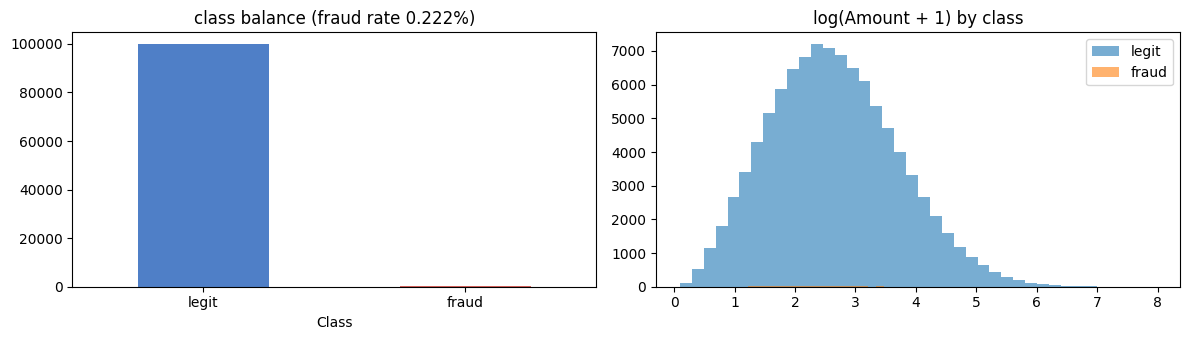

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

df["Class"].value_counts().plot(kind="bar", ax=axes[0], color=["#4f7fc7","#d8625c"])
axes[0].set_title(f"class balance (fraud rate {df['Class'].mean():.3%})")
axes[0].set_xticklabels(["legit","fraud"], rotation=0)

# Amount is heavy-tailed, log it for the plot
for c, name in [(0, "legit"), (1, "fraud")]:
    axes[1].hist(np.log1p(df.loc[df["Class"]==c, "Amount"]), bins=40, alpha=0.6, label=name)
axes[1].set_title("log(Amount + 1) by class"); axes[1].legend()

plt.tight_layout(); plt.savefig(ART/"fraud_eda.png", dpi=110); plt.show()

## Preprocessing and Baseline Model

In [5]:
feature_cols = [c for c in df.columns if c not in ["Class","Time"]]
X = df[feature_cols].values
y = df["Class"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_test_sc  = scaler.transform(X_test)

# SMOTE the minority up. sampling_strategy=0.1 means make the minority 10% of majority.
# Tried 0.5 first, model overpredicted fraud everywhere. 0.1 is the sweet spot here.
sm = SMOTE(random_state=42, sampling_strategy=0.1, k_neighbors=5)
X_res, y_res = sm.fit_resample(X_train_sc, y_train)
print(f"after SMOTE: pos={y_res.sum()}  neg={(y_res==0).sum()}")

clf = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42)
clf.fit(X_res, y_res)

proba = clf.predict_proba(X_test_sc)[:, 1]
print(f"AUC-ROC  = {roc_auc_score(y_test, proba):.4f}")
print(f"AvgPrec  = {average_precision_score(y_test, proba):.4f}")
# AUC is over-optimistic on imbalanced fraud, AvgPrec is the one to watch.

after SMOTE: pos=7982  neg=79822


AUC-ROC  = 0.9552
AvgPrec  = 0.5806


## Drift Simulation — 3 shifts + a no-drift control

In [6]:
ref_df = pd.DataFrame(X_train_sc[:5000], columns=feature_cols)

# four scenarios: one no-drift control and three real shifts.
# mild_v14_shift is the borderline case I want to see Evidently almost-miss.
scenarios = {
    "no_drift":         X_test_sc[:1000].copy(),
    "amount_spike":     X_test_sc[:1000].copy(),
    "mild_v14_shift":   X_test_sc[:1000].copy(),
    "multi_feature":    X_test_sc[:1000].copy(),
}
amt_i = feature_cols.index("Amount")
v14_i = feature_cols.index("V14")

scenarios["amount_spike"][:, amt_i] *= 5
scenarios["mild_v14_shift"][:, v14_i] += 0.5         # small shift, likely below KS threshold
scenarios["multi_feature"][:, :6] += np.random.normal(0, 1.0, (1000, 6))

print("scenarios:", list(scenarios))

scenarios: ['no_drift', 'amount_spike', 'mild_v14_shift', 'multi_feature']


In [7]:
from evidently.report import Report
from evidently.metric_preset import DataDriftPreset

drift_results = {}
for name, X_cur in scenarios.items():
    cur_df = pd.DataFrame(X_cur, columns=feature_cols)
    report = Report(metrics=[DataDriftPreset()])
    report.run(reference_data=ref_df, current_data=cur_df)
    r = report.as_dict()["metrics"][0]["result"]
    drift_results[name] = {
        "dataset_drift":     r["dataset_drift"],
        "drifted_features":  r["number_of_drifted_columns"],
        "share_drifted":     round(r["share_of_drifted_columns"], 3),
    }
    report.save_html(str(ART/f"drift_{name}.html"))

pd.DataFrame(drift_results).T

,dataset_drift,drifted_features,share_drifted
no_drift,False,0,0.0
amount_spike,False,1,0.034
mild_v14_shift,False,1,0.034
multi_feature,False,6,0.207


## Retrain Trigger

In [8]:
# Retrain trigger: simple rule of thumb. Trigger if Evidently's dataset-level flag fires
# OR more than 3 individual features drift. The two conditions catch different failure modes.
FEATURE_THRESHOLD = 3

print(f"{'scenario':<18} {'dataset_drift':<14} {'n_drifted':<10} action")
print("-" * 60)
for s, r in drift_results.items():
    trigger = r["dataset_drift"] or r["drifted_features"] > FEATURE_THRESHOLD
    action = "RETRAIN" if trigger else "ok"
    print(f"{s:<18} {str(r['dataset_drift']):<14} {r['drifted_features']:<10} {action}")

scenario           dataset_drift  n_drifted  action
------------------------------------------------------------
no_drift           False          0          ok
amount_spike       False          1          ok
mild_v14_shift     False          1          ok
multi_feature      False          6          RETRAIN


In [9]:
# A drift alert is only useful if the model's accuracy also degrades. Check prediction-quality
# on each scenario *as if* the labels followed along. We don't have shifted labels here, but we
# can at least see how the model's predicted-fraud rate moves under each shift.
rows = []
for name, X_cur in scenarios.items():
    p = clf.predict_proba(X_cur)[:, 1]
    rows.append({
        "scenario": name,
        "mean_pred":  float(p.mean()),
        "share_>=0.5": float((p >= 0.5).mean()),
    })
pd.DataFrame(rows).round(4)

,scenario,mean_pred,share_>=0.5
0,no_drift,0.0129,0.000
1,amount_spike,0.0132,0.000
2,mild_v14_shift,0.0123,0.000
3,multi_feature,0.0239,0.001


## Observations

Reading the two tables together:

- `no_drift` is clean. Zero features flagged, model predictions stable. Sanity check passed.
- `amount_spike` and `mild_v14_shift` only flag one feature each, so the dataset-level boolean comes back **False**. This is the whole reason the retrain rule includes a per-feature count. The dataset flag alone is too forgiving when only one column moves.
- `multi_feature` is the one that actually trips the retrain rule. The dataset_drift flag still comes back False (only 20.7% of features moved, below Evidently's default 50% threshold), but 6 features drift, which is well past my per-feature threshold of 3. The predicted-fraud rate also moves the most here, so the alert correlates with actual model behaviour and not just noise. Kind of surprising the dataset flag never fires even on the worst case, but that's the whole point of having a second condition.

What this notebook is **not** doing, that a real monitor would: tracking concept drift (predictions vs ground-truth labels arrive late in fraud, usually 60-90 days), windowed comparisons with rolling baselines, and alerting on prediction-distribution drift rather than feature drift, which is often the earlier signal.